# 📊 Khám Phá Dữ Liệu Học Tập (OULAD) & Kỹ Thuật Trích Xuất Đặc Trưng
> **Đề tài:** Hệ Thống Gợi Ý Chiến Lược Học Tập Cá Nhân Hóa (KLTN 13 - HUIT)  
> **Tập dữ liệu:** Open University Learning Analytics Dataset (OULAD)  

Notebook này thực hiện:
1. Tải và phân tích cấu trúc 7 bảng dữ liệu OULAD (`studentInfo`, `studentVle`, `studentAssessment`, `assessments`, `vle`, `courses`, `studentRegistration`).
2. Phân tích phân phối kết quả học tập (`Pass`, `Fail`, `Distinction`, `Withdrawn`) và tương quan hành vi.
3. Trích xuất đặc trưng đa chiều (Nhân khẩu học, Điểm đánh giá, Hành vi tương tác LMS theo mốc thời gian).
4. Xây dựng pipeline tiền xử lý và lưu trữ tập dữ liệu sạch vào `data/processed/`.

In [1]:
import os
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Thêm thư mục gốc vào sys.path để nạp packages
sys.path.append(os.path.abspath('..'))

# Cấu hình trực quan hóa
sns.set_theme(style='whitegrid')
plt.rcParams['figure.figsize'] = (10, 5)
plt.rcParams['font.sans-serif'] = 'Segoe UI'
print('Đã nạp các thư viện phân tích dữ liệu thành công!')

C:\Users\NGUYEN\AppData\Local\Programs\Python\Python312\Lib\site-packages\seaborn\_statistics.py:32: UserWarning: A NumPy version >=1.23.5 and <2.3.0 is required for this version of SciPy (detected version 2.5.2)
  from scipy.stats import gaussian_kde


Đã nạp các thư viện phân tích dữ liệu thành công!


## 1. Tải và Khảo Sát Các Bảng Dữ Liệu OULAD

In [2]:
data_dir = '../data/raw'

df_info = pd.read_csv(os.path.join(data_dir, 'studentInfo.csv'))
df_reg = pd.read_csv(os.path.join(data_dir, 'studentRegistration.csv'))
df_assess = pd.read_csv(os.path.join(data_dir, 'assessments.csv'))
df_stud_assess = pd.read_csv(os.path.join(data_dir, 'studentAssessment.csv'))
df_vle = pd.read_csv(os.path.join(data_dir, 'vle.csv'))
df_courses = pd.read_csv(os.path.join(data_dir, 'courses.csv'))

print(f'studentInfo shape: {df_info.shape}')
print(f'studentRegistration shape: {df_reg.shape}')
print(f'assessments shape: {df_assess.shape}')
print(f'studentAssessment shape: {df_stud_assess.shape}')
print(f'vle shape: {df_vle.shape}')
print(f'courses shape: {df_courses.shape}')
df_info.head()

studentInfo shape: (32593, 12)
studentRegistration shape: (32593, 5)
assessments shape: (206, 6)
studentAssessment shape: (173912, 5)
vle shape: (6364, 6)
courses shape: (22, 3)


,code_module,code_presentation,id_student,gender,region,highest_education,imd_band,age_band,num_of_prev_attempts,studied_credits,disability,final_result
0,AAA,2013J,11391,M,East Anglian Region,HE Qualification,90-100%,55<=,0,240,N,Pass
1,AAA,2013J,28400,F,Scotland,HE Qualification,20-30%,35-55,0,60,N,Pass
2,AAA,2013J,30268,F,North Western Region,A Level or Equivalent,30-40%,35-55,0,60,Y,Withdrawn
3,AAA,2013J,31604,F,South East Region,A Level or Equivalent,50-60%,35-55,0,60,N,Pass
4,AAA,2013J,32885,F,West Midlands Region,Lower Than A Level,50-60%,0-35,0,60,N,Pass


## 2. Phân Tích Phân Phối Kết Quả Học Tập (Target Distribution)

C:\Users\NGUYEN\AppData\Local\Temp\ipykernel_17452\656579032.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.countplot(data=df_info, x='final_result', palette=palette, order=['Distinction', 'Pass', 'Fail', 'Withdrawn'])


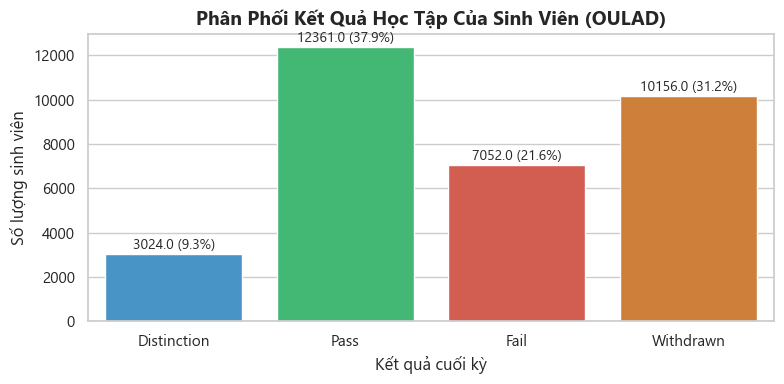

In [3]:
plt.figure(figsize=(8, 4))
palette = {'Pass': '#2ecc71', 'Distinction': '#3498db', 'Fail': '#e74c3c', 'Withdrawn': '#e67e22'}
ax = sns.countplot(data=df_info, x='final_result', palette=palette, order=['Distinction', 'Pass', 'Fail', 'Withdrawn'])
plt.title('Phân Phối Kết Quả Học Tập Của Sinh Viên (OULAD)', fontsize=14, fontweight='bold')
plt.xlabel('Kết quả cuối kỳ', fontsize=12)
plt.ylabel('Số lượng sinh viên', fontsize=12)

total = len(df_info)
for p in ax.patches:
    height = p.get_height()
    ax.annotate(f'{height} ({height/total*100:.1f}%)',
                (p.get_x() + p.get_width() / 2., height + 100),
                ha='center', va='bottom', fontsize=10)
plt.tight_layout()
plt.show()

## 3. Trích Xuất Đặc Trưng (Feature Engineering)
Sử dụng module `packages/ml/src/features/engineering.py` để tổng hợp dữ liệu từ 7 bảng thành một tập đặc trưng đa chiều.

In [4]:
from packages.ml.src.features.engineering import extract_oulad_features

print('Bắt đầu quá trình trích xuất đặc trưng...')
df_features = extract_oulad_features(data_dir=data_dir)
print(f'Kích thước bảng dữ liệu sau trích xuất: {df_features.shape}')
print('Danh sách các thuộc tính:')
print(df_features.columns.tolist())
df_features.head()

Bắt đầu quá trình trích xuất đặc trưng...


Kích thước bảng dữ liệu sau trích xuất: (32593, 33)
Danh sách các thuộc tính:
['code_module', 'code_presentation', 'id_student', 'gender', 'region', 'highest_education', 'imd_band', 'age_band', 'num_of_prev_attempts', 'studied_credits', 'disability', 'final_result', 'date_registration', 'date_unregistration', 'avg_score', 'min_score', 'max_score', 'std_score', 'total_assessments_taken', 'late_submissions', 'weighted_avg_score', 'total_clicks', 'active_days', 'clicks_early', 'clicks_mid', 'clicks_late', 'clicks_forumng', 'clicks_homepage', 'clicks_oucontent', 'clicks_quiz', 'clicks_resource', 'clicks_subpage', 'clicks_url']


,code_module,code_presentation,id_student,gender,region,highest_education,imd_band,age_band,num_of_prev_attempts,studied_credits,...,clicks_early,clicks_mid,clicks_late,clicks_forumng,clicks_homepage,clicks_oucontent,clicks_quiz,clicks_resource,clicks_subpage,clicks_url
0,AAA,2013J,11391,M,East Anglian Region,HE Qualification,90-100%,55<=,0,240,...,424.0,168.0,342.0,193.0,138.0,553.0,0.0,13.0,32.0,5.0
1,AAA,2013J,28400,F,Scotland,HE Qualification,20-30%,35-55,0,60,...,618.0,256.0,561.0,417.0,324.0,537.0,0.0,12.0,87.0,48.0
2,AAA,2013J,30268,F,North Western Region,A Level or Equivalent,30-40%,35-55,0,60,...,281.0,0.0,0.0,126.0,59.0,66.0,0.0,4.0,22.0,4.0
3,AAA,2013J,31604,F,South East Region,A Level or Equivalent,50-60%,35-55,0,60,...,540.0,539.0,1079.0,634.0,432.0,836.0,0.0,19.0,144.0,90.0
4,AAA,2013J,32885,F,West Midlands Region,Lower Than A Level,50-60%,0-35,0,60,...,567.0,155.0,312.0,194.0,204.0,494.0,0.0,45.0,79.0,14.0


## 4. Phân Tích Mối Quan Hệ Giữa Tương Tác VLE và Kết Quả Học Tập

C:\Users\NGUYEN\AppData\Local\Temp\ipykernel_17452\3072932337.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_features, x='final_result', y='active_days', ax=axes[0], palette=palette, order=['Distinction', 'Pass', 'Fail', 'Withdrawn'])
C:\Users\NGUYEN\AppData\Local\Temp\ipykernel_17452\3072932337.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_features, x='final_result', y='avg_score', ax=axes[1], palette=palette, order=['Distinction', 'Pass', 'Fail', 'Withdrawn'])


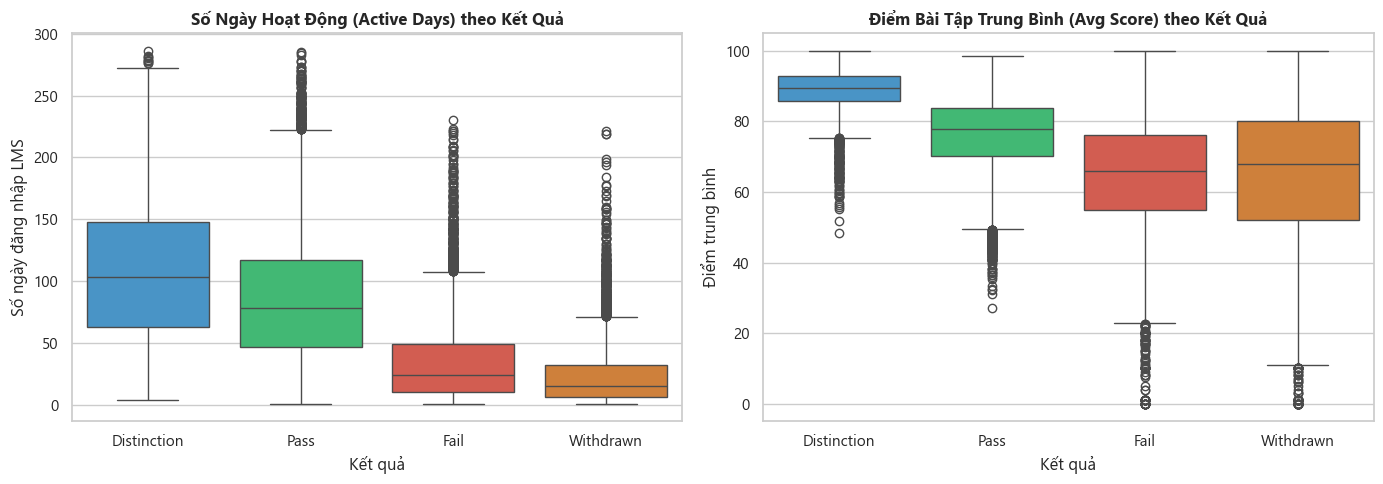

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Biểu đồ 1: Số ngày hoạt động theo kết quả
sns.boxplot(data=df_features, x='final_result', y='active_days', ax=axes[0], palette=palette, order=['Distinction', 'Pass', 'Fail', 'Withdrawn'])
axes[0].set_title('Số Ngày Hoạt Động (Active Days) theo Kết Quả', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Kết quả')
axes[0].set_ylabel('Số ngày đăng nhập LMS')

# Biểu đồ 2: Điểm đánh giá trung bình theo kết quả
sns.boxplot(data=df_features, x='final_result', y='avg_score', ax=axes[1], palette=palette, order=['Distinction', 'Pass', 'Fail', 'Withdrawn'])
axes[1].set_title('Điểm Bài Tập Trung Bình (Avg Score) theo Kết Quả', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Kết quả')
axes[1].set_ylabel('Điểm trung bình')

plt.tight_layout()
plt.show()

## 5. Lưu Dữ Liệu Đã Trích Xuất Đặc Trưng

In [6]:
processed_dir = '../data/processed'
os.makedirs(processed_dir, exist_ok=True)
out_path = os.path.join(processed_dir, 'oulad_features_engineered.csv')
df_features.to_csv(out_path, index=False)
print(f'Đã lưu tập đặc trưng thành công vào: {out_path}')

Đã lưu tập đặc trưng thành công vào: ../data/processed\oulad_features_engineered.csv
